In [6]:
%pip install pandas numpy matplotlib seaborn scikit-learn lightgbm


[notice] A new release of pip available: 22.3 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_curve
)
import warnings
warnings.filterwarnings("ignore")

In [8]:
SEED = 42
np.random.seed(SEED)
 
SAVE_SUBMISSION = True
 
seeds = [42, 2021, 7, 99, 123, 555, 777, 1001, 2024, 9999]
n_folds = 5

In [11]:
train = pd.read_csv("../data/train.csv")
test = pd.read_csv("../data/test.csv")
# Keep test ids for the final submission
test_ids = test["id"].copy()
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Order rate:", round(train["order_placed"].mean(), 4))

Train shape: (297236, 18)
Test shape: (99639, 17)
Order rate: 0.0291


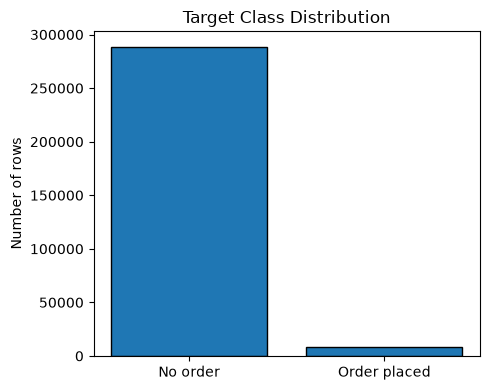

In [12]:
class_counts = train["order_placed"].value_counts().sort_index()
 
plt.figure(figsize=(5, 4))
plt.bar(["No order", "Order placed"], class_counts.values, edgecolor="black")
plt.title("Target Class Distribution")
plt.ylabel("Number of rows")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
train["is_train"] = 1
test["is_train"] = 0
test["order_placed"] = -1
 
combined = pd.concat([train, test], axis=0, ignore_index=True)
 
# Convert datetime columns
for col in ["f3", "f4", "f5"]:
    combined[col] = pd.to_datetime(combined[col], errors="coerce", utc=True)

In [14]:
combined["session_duration_min"] = (
    (combined["f4"] - combined["f3"]).dt.total_seconds() / 60
).clip(0, 1000)
 
combined["idle_before_end_min"] = (
    (combined["f4"] - combined["f5"]).dt.total_seconds() / 60
).clip(0, 1000)
 
combined["session_hour"] = (
    (combined["f3"].dt.hour.fillna(0) + combined["f6"].fillna(0) / 60) % 24
).round().astype(int)
 
combined["is_meal_time"] = combined["session_hour"].apply(
    lambda h: 1 if (12 <= h <= 14) or (18 <= h <= 21) else 0
)
 
combined["time_to_interaction"] = (
    (combined["f5"] - combined["f3"]).dt.total_seconds() / 60
).clip(0, 1000)
 
combined["day_of_week"] = combined["f3"].dt.dayofweek.fillna(-1).astype(int)
combined["is_weekend"] = combined["day_of_week"].isin([5, 6]).astype(int)
 
combined["session_over_30min"] = (combined["session_duration_min"] > 30).astype(int)
 
combined["active_ratio"] = np.where(
    combined["session_duration_min"] > 0,
    combined["time_to_interaction"] / combined["session_duration_min"],
    0
).clip(0, 1)
 
combined["action_velocity"] = combined["f8"] / (combined["session_duration_min"] + 1)
 
combined["has_items"] = (combined["f10"] > 0).astype(int)
 
combined["avg_item_value"] = np.where(
    combined["f10"] > 0, combined["f11"] / combined["f10"], 0
)
combined["has_promotion"] = combined["f12"].notna().astype(int)
 
combined["items_and_accepted"] = (
    (combined["f10"] > 0) & (combined["f17"] == "ACCEPTED")
).astype(int)
 
combined["items_and_strong_promo"] = (
    (combined["f10"] > 0) & (combined["f12"].isin(["S", "C"]))
).astype(int)

combined["f12"] = combined["f12"].fillna("NONE")
combined["f17"] = combined["f17"].fillna("NONE")
 
for c in ["f13", "f14", "f15"]:
    combined[c] = combined[c].fillna(0)

combined["many_promos_shown"] = (combined["f15"] >= 3).astype(int)
 
combined["accepted_strong_promo"] = (
    (combined["f17"] == "ACCEPTED") & (combined["f12"].isin(["S", "C"]))
).astype(int)

combined["meets_promo_threshold"] = (
    (combined["f11"] > 0) & (combined["f14"] > 0) & (combined["f11"] >= combined["f14"])
).astype(int)
 
combined["promo_gap_ratio"] = np.where(
    combined["f14"] > 0, combined["f11"] / combined["f14"], 0
)
 
combined["discount_to_cart_ratio"] = np.where(
    combined["f11"] > 0, combined["f13"] / combined["f11"], 0
)
 
combined["cart_minus_promo_min"] = combined["f11"] - combined["f14"]
 
combined["offers_declined_ratio"] = np.where(
    combined["f15"] > 0, combined["f8"] / combined["f15"], 0
)
 
combined["discount_per_item"] = np.where(
    combined["f10"] > 0, combined["f13"] / combined["f10"], 0
)

combined["accepted_and_near_threshold"] = (
    (combined["f17"] == "ACCEPTED") & (combined["promo_gap_ratio"] >= 0.8)
).astype(int)
 
combined["declines_per_cart_value"] = np.where(
    combined["f11"] > 0, combined["f8"] / combined["f11"], 0
)
 
combined["over30_and_items"] = (
    (combined["session_over_30min"] == 1) & (combined["f10"] > 0)
).astype(int)

combined["f12_f17_cross"] = combined["f12"].astype(str) + "_" + combined["f17"].astype(str)
combined["f9_f17_cross"] = combined["f9"].astype(str) + "_" + combined["f17"].astype(str)
combined["f7_f12_cross"] = combined["f7"].astype(str) + "_" + combined["f12"].astype(str)


In [15]:
freq_cols = [
    "f7", "f9", "f12", "f17",
    "f12_f17_cross", "f9_f17_cross", "f7_f12_cross",
    "f10", "f15"
]
 
for col in freq_cols:
    value_counts = combined[col].value_counts()
    freq_map = combined[col].value_counts(normalize=True)
    combined[col + "_count"] = combined[col].map(value_counts).fillna(0)
    combined[col + "_freq"] = combined[col].map(freq_map).fillna(0)

In [16]:
cat_cols = [
    "f7", "f9", "f12", "f17",
    "f12_f17_cross", "f9_f17_cross", "f7_f12_cross"
]
 
for col in cat_cols:
    combined[col] = combined[col].astype("category")

In [17]:
drop_cols = ["f3", "f4", "f5", "id", "f2", "f6", "is_train", "order_placed"]
 
X = combined[combined["is_train"] == 1].drop(columns=drop_cols)
y = combined[combined["is_train"] == 1]["order_placed"].astype(int)
X_test = combined[combined["is_train"] == 0].drop(columns=drop_cols)
 
X = X.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)
 
print("Train rows:", len(X))
print("Number of features:", X.shape[1])

Train rows: 297236
Number of features: 58


In [18]:
def best_f1_threshold(y_true, probs):
    thresholds = np.arange(0.01, 1.00, 0.01)
    f1_scores = []
    for t in thresholds:
        preds = (probs >= t).astype(int)
        f1_scores.append(f1_score(y_true, preds, zero_division=0))
    best_index = int(np.argmax(f1_scores))
    return thresholds[best_index], f1_scores[best_index]
 
 
def calculate_metrics(model_name, y_true, probs, evaluation_type):
    preds_05 = (probs >= 0.5).astype(int)
 
    auc = roc_auc_score(y_true, probs)
    accuracy = accuracy_score(y_true, preds_05)
    precision = precision_score(y_true, preds_05, zero_division=0)
    recall = recall_score(y_true, preds_05, zero_division=0)
    f1 = f1_score(y_true, preds_05, zero_division=0)
    best_t, best_f1 = best_f1_threshold(y_true, probs)
 
    return {
        "Model": model_name,
        "Evaluation": evaluation_type,
        "AUC": auc,
        "Accuracy": accuracy,
        "Precision_0.5": precision,
        "Recall_0.5": recall,
        "F1_0.5": f1,
        "Best_F1": best_f1,
        "Best_F1_Threshold": best_t,
    }
 
 
def print_model_result(result):
    print()
    print("Model:", result["Model"])
    print("Evaluation:", result["Evaluation"])
    print("AUC:", round(result["AUC"], 5))
    print("Accuracy:", round(result["Accuracy"], 5))
    print("F1 at 0.5:", round(result["F1_0.5"], 5))
    print("Best F1:", round(result["Best_F1"], 5))
    print("Best F1 threshold:", round(result["Best_F1_Threshold"], 2))

In [19]:
X_train_base, X_val_base, y_train_base, y_val_base = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
 
num_cols = [c for c in X.columns if c not in cat_cols]
 
preprocessor_scaled = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])
 
preprocessor_tree = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])
 
results = []

In [20]:
log_reg_pipe = Pipeline([
    ("preprocess", preprocessor_scaled),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])
 
log_reg_pipe.fit(X_train_base, y_train_base)
log_reg_probs = log_reg_pipe.predict_proba(X_val_base)[:, 1]
 
result = calculate_metrics("Logistic Regression", y_val_base, log_reg_probs, "Holdout validation")
results.append(result)
print_model_result(result)


Model: Logistic Regression
Evaluation: Holdout validation
AUC: 0.96239
Accuracy: 0.86733
F1 at 0.5: 0.30123
Best F1: 0.4284
Best F1 threshold: 0.88


In [21]:
knn_sample_size = min(15000, len(X_train_base))
 
X_knn_train, _, y_knn_train, _ = train_test_split(
    X_train_base, y_train_base,
    train_size=knn_sample_size, stratify=y_train_base, random_state=SEED
)
 
knn_pipe = Pipeline([
    ("preprocess", preprocessor_scaled),
    ("model", KNeighborsClassifier(n_neighbors=15, n_jobs=-1)),
])
 
knn_pipe.fit(X_knn_train, y_knn_train)
knn_probs = knn_pipe.predict_proba(X_val_base)[:, 1]
 
result = calculate_metrics("KNN", y_val_base, knn_probs, "Holdout validation, trained on small sample")
results.append(result)
print_model_result(result)


Model: KNN
Evaluation: Holdout validation, trained on small sample
AUC: 0.92225
Accuracy: 0.97048
F1 at 0.5: 0.19012
Best F1: 0.39017
Best F1 threshold: 0.21


In [22]:
dt_pipe = Pipeline([
    ("preprocess", preprocessor_tree),
    ("model", DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=SEED
    )),
])
 
dt_pipe.fit(X_train_base, y_train_base)
dt_probs = dt_pipe.predict_proba(X_val_base)[:, 1]
 
result = calculate_metrics("Decision Tree depth 12", y_val_base, dt_probs, "Holdout validation")
results.append(result)
print_model_result(result)


Model: Decision Tree depth 12
Evaluation: Holdout validation
AUC: 0.94068
Accuracy: 0.89426
F1 at 0.5: 0.34081
Best F1: 0.44043
Best F1 threshold: 0.93


In [23]:
rf_pipe = Pipeline([
    ("preprocess", preprocessor_tree),
    ("model", RandomForestClassifier(
        n_estimators=100, max_depth=15, min_samples_leaf=10,
        class_weight="balanced_subsample", n_jobs=-1, random_state=SEED
    )),
])
 
rf_pipe.fit(X_train_base, y_train_base)
rf_probs = rf_pipe.predict_proba(X_val_base)[:, 1]
 
result = calculate_metrics("Random Forest 100 trees", y_val_base, rf_probs, "Holdout validation")
results.append(result)
print_model_result(result)


Model: Random Forest 100 trees
Evaluation: Holdout validation
AUC: 0.96679
Accuracy: 0.90028
F1 at 0.5: 0.35844
Best F1: 0.45584
Best F1 threshold: 0.88


In [24]:
lgbm_reg_params = {
    "n_estimators": 1000,
    "learning_rate": 0.03,
    "num_leaves": 63,
    "min_child_samples": 30,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "n_jobs": -1,
    "random_state": SEED,
    "verbosity": -1,
}
 
lgbm_reg = lgb.LGBMClassifier(**lgbm_reg_params)
 
lgbm_reg.fit(
    X_train_base, y_train_base,
    eval_set=[(X_val_base, y_val_base)],
    eval_metric="auc",
    categorical_feature=cat_cols,
    callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
)
 
lgbm_reg_probs = lgbm_reg.predict_proba(X_val_base)[:, 1]
 
result = calculate_metrics("LightGBM regularized", y_val_base, lgbm_reg_probs, "Holdout validation")
results.append(result)
print_model_result(result)


Model: LightGBM regularized
Evaluation: Holdout validation
AUC: 0.97206
Accuracy: 0.97406
F1 at 0.5: 0.3701
Best F1: 0.50945
Best F1 threshold: 0.26


In [25]:
te_cols = [
    "f7", "f9", "f12", "f17",
    "f12_f17_cross", "f9_f17_cross", "f7_f12_cross"
]
 
 
def add_target_encoding(X_tr, X_val, X_te, y_tr, smooth=100):
    global_mean = y_tr.mean()
 
    for col in te_cols:
        temp = pd.DataFrame({
            "col": X_tr[col].astype(str).values,
            "target": y_tr.values,
        })
        stats = temp.groupby("col")["target"].agg(["mean", "count"])
        smooth_values = (
            stats["count"] * stats["mean"] + smooth * global_mean
        ) / (stats["count"] + smooth)
 
        new_col = col + "_te"
        X_tr[new_col] = X_tr[col].astype(str).map(smooth_values).fillna(global_mean)
        X_val[new_col] = X_val[col].astype(str).map(smooth_values).fillna(global_mean)
        X_te[new_col] = X_te[col].astype(str).map(smooth_values).fillna(global_mean)
 
    return X_tr, X_val, X_te

In [27]:
lgb_params = {
    "n_estimators": 4000,
    "learning_rate": 0.02,
    "num_leaves": 63,
    "min_child_samples": 30,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "n_jobs": -1,
    "verbosity": -1,
}
all_oof_preds = np.zeros(len(X))
all_test_preds = np.zeros(len(X_test))
all_fold_aucs = []
 
feature_importance_sum = None
feature_importance_count = 0
 
for seed in seeds:
    print()
    print("=" * 70)
    print("Seed", seed)
    print("=" * 70)
 
    kf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
 
    oof_preds = np.zeros(len(X))
    test_preds = np.zeros(len(X_test))
 
    for fold, (train_idx, val_idx) in enumerate(kf.split(X, y), start=1):
        X_train = X.iloc[train_idx].copy()
        X_val = X.iloc[val_idx].copy()
        X_te = X_test.copy()
 
        y_train = y.iloc[train_idx]
        y_val = y.iloc[val_idx]
 
        X_train, X_val, X_te = add_target_encoding(
            X_train, X_val, X_te, y_train, smooth=100
        )
 
        params = lgb_params.copy()
        params["random_state"] = seed
 
        model = lgb.LGBMClassifier(**params)
 
        model.fit(
            X_train, y_train,
            eval_set=[(X_val, y_val)],
            eval_metric="auc",
            categorical_feature=cat_cols,
            callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
        )
 
        val_pred = model.predict_proba(X_val)[:, 1]
        test_pred = model.predict_proba(X_te)[:, 1]
 
        oof_preds[val_idx] = val_pred
        test_preds += test_pred / kf.n_splits
 
        fold_auc = roc_auc_score(y_val, val_pred)
        all_fold_aucs.append(fold_auc)
 
        # Keep average feature importance across folds/seeds
        fold_importance = pd.Series(model.feature_importances_, index=X_train.columns)
 
        if feature_importance_sum is None:
            feature_importance_sum = fold_importance.copy()
        else:
            feature_importance_sum = feature_importance_sum.add(fold_importance, fill_value=0)
 
        feature_importance_count += 1
 
        print(
            "Seed", seed,
            "| Fold", fold,
            "| AUC:", round(fold_auc, 6),
            "| Best iteration:", model.best_iteration_,
        )
 
    seed_auc = roc_auc_score(y, oof_preds)
    print("Seed", seed, "OOF AUC:", round(seed_auc, 6))
 
    all_oof_preds += oof_preds / len(seeds)
    all_test_preds += test_preds / len(seeds)


Seed 42
Seed 42 | Fold 1 | AUC: 0.971514 | Best iteration: 519
Seed 42 | Fold 2 | AUC: 0.972802 | Best iteration: 499
Seed 42 | Fold 3 | AUC: 0.971318 | Best iteration: 455
Seed 42 | Fold 4 | AUC: 0.972943 | Best iteration: 882
Seed 42 | Fold 5 | AUC: 0.973342 | Best iteration: 529
Seed 42 OOF AUC: 0.97235

Seed 2021
Seed 2021 | Fold 1 | AUC: 0.973072 | Best iteration: 869
Seed 2021 | Fold 2 | AUC: 0.970741 | Best iteration: 617
Seed 2021 | Fold 3 | AUC: 0.973052 | Best iteration: 725
Seed 2021 | Fold 4 | AUC: 0.973146 | Best iteration: 454
Seed 2021 | Fold 5 | AUC: 0.972379 | Best iteration: 579
Seed 2021 OOF AUC: 0.97244

Seed 7
Seed 7 | Fold 1 | AUC: 0.972122 | Best iteration: 524
Seed 7 | Fold 2 | AUC: 0.973454 | Best iteration: 709
Seed 7 | Fold 3 | AUC: 0.973705 | Best iteration: 950
Seed 7 | Fold 4 | AUC: 0.971376 | Best iteration: 633
Seed 7 | Fold 5 | AUC: 0.972297 | Best iteration: 862
Seed 7 OOF AUC: 0.972528

Seed 99
Seed 99 | Fold 1 | AUC: 0.972506 | Best iteration: 498
S

In [28]:
final_oof_auc = roc_auc_score(y, all_oof_preds)
 
advanced_result = calculate_metrics(
    "LightGBM multi-seed target encoding", y, all_oof_preds, "OOF cross-validation"
)
results.append(advanced_result)
 
print()
print("=" * 70)
print("Final CV summary")
print("=" * 70)
print("Mean fold AUC:", round(np.mean(all_fold_aucs), 6))
print("Std fold AUC:", round(np.std(all_fold_aucs), 6))
print("Min fold AUC:", round(np.min(all_fold_aucs), 6))
print("Max fold AUC:", round(np.max(all_fold_aucs), 6))
print("Final blended OOF AUC:", round(final_oof_auc, 6))
print("Predicted order rate:", round(all_test_preds.mean() * 100, 3), "%")
 
print_model_result(advanced_result)


Final CV summary
Mean fold AUC: 0.972521
Std fold AUC: 0.000749
Min fold AUC: 0.970501
Max fold AUC: 0.973705
Final blended OOF AUC: 0.97302
Predicted order rate: 2.926 %

Model: LightGBM multi-seed target encoding
Evaluation: OOF cross-validation
AUC: 0.97302
Accuracy: 0.97393
F1 at 0.5: 0.35444
Best F1: 0.51795
Best F1 threshold: 0.24


In [29]:
results_table = pd.DataFrame(results)
 
# Round only for printing
results_table_print = results_table.copy()
for col in ["AUC", "Accuracy", "Precision_0.5", "Recall_0.5", "F1_0.5", "Best_F1", "Best_F1_Threshold"]:
    results_table_print[col] = results_table_print[col].round(5)
 
results_table_print = results_table_print.sort_values("AUC", ascending=False).reset_index(drop=True)
 
print()
print("=" * 70)
print("Model comparison table")
print("=" * 70)
print(results_table_print.to_string(index=False))
 
results_table_print.to_csv("model_comparison_table.csv", index=False)


Model comparison table
                              Model                                  Evaluation     AUC  Accuracy  Precision_0.5  Recall_0.5  F1_0.5  Best_F1  Best_F1_Threshold
LightGBM multi-seed target encoding                        OOF cross-validation 0.97302   0.97393        0.63341     0.24607 0.35444  0.51795               0.24
               LightGBM regularized                          Holdout validation 0.97206   0.97406        0.63004     0.26200 0.37010  0.50945               0.26
            Random Forest 100 trees                          Holdout validation 0.96679   0.90028        0.22048     0.95778 0.35844  0.45584               0.88
                Logistic Regression                          Holdout validation 0.96239   0.86733        0.17786     0.98323 0.30123  0.42840               0.88
             Decision Tree depth 12                          Holdout validation 0.94068   0.89426        0.20815     0.93985 0.34081  0.44043               0.93
          

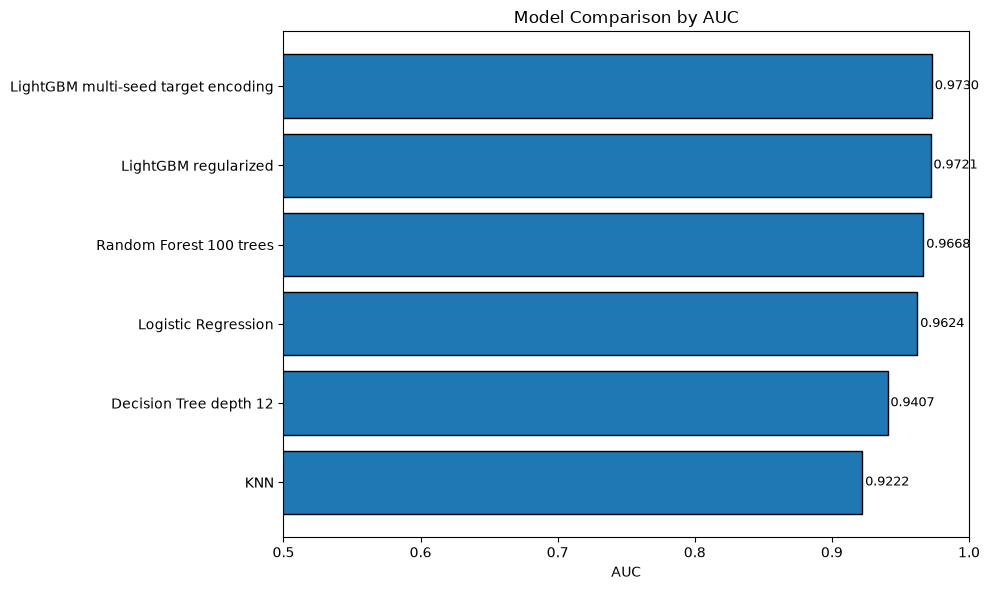

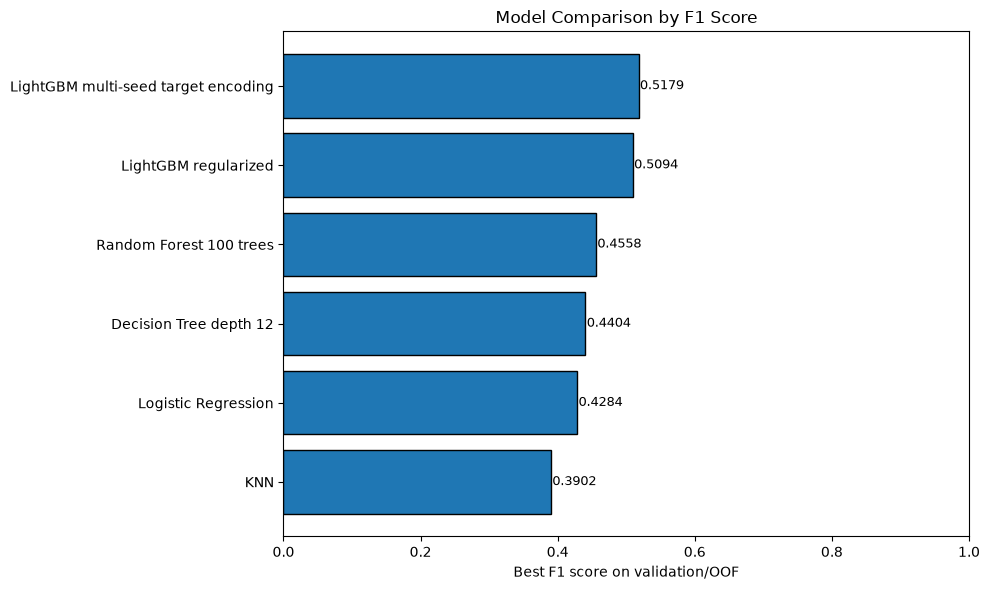

In [30]:
plot_table = results_table.sort_values("AUC", ascending=True)
 
plt.figure(figsize=(10, 6))
plt.barh(plot_table["Model"], plot_table["AUC"], edgecolor="black")
plt.xlabel("AUC")
plt.title("Model Comparison by AUC")
plt.xlim(0.5, 1.0)
for i, value in enumerate(plot_table["AUC"]):
    plt.text(value + 0.002, i, f"{value:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("model_comparison_auc.png", dpi=150, bbox_inches="tight")
plt.show()
 
plot_table_f1 = results_table.sort_values("Best_F1", ascending=True)
 
plt.figure(figsize=(10, 6))
plt.barh(plot_table_f1["Model"], plot_table_f1["Best_F1"], edgecolor="black")
plt.xlabel("Best F1 score on validation/OOF")
plt.title("Model Comparison by F1 Score")
plt.xlim(0, 1.0)
for i, value in enumerate(plot_table_f1["Best_F1"]):
    plt.text(value + 0.002, i, f"{value:.4f}", va="center", fontsize=9)
plt.tight_layout()
plt.savefig("model_comparison_f1.png", dpi=150, bbox_inches="tight")
plt.show()

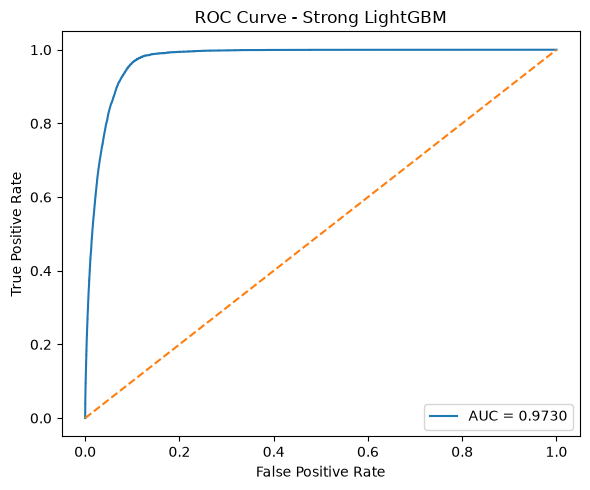

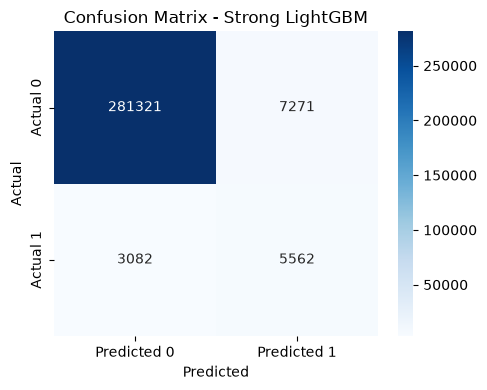

In [31]:
best_threshold = advanced_result["Best_F1_Threshold"]
advanced_preds = (all_oof_preds >= best_threshold).astype(int)
 
fpr, tpr, _ = roc_curve(y, all_oof_preds)
 
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {final_oof_auc:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Strong LightGBM")
plt.legend()
plt.tight_layout()
plt.savefig("roc_curve_strong_lgbm.png", dpi=150, bbox_inches="tight")
plt.show()
 
cm = confusion_matrix(y, advanced_preds)
 
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"],
)
plt.title("Confusion Matrix - Strong LightGBM")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix_strong_lgbm.png", dpi=150, bbox_inches="tight")
plt.show()

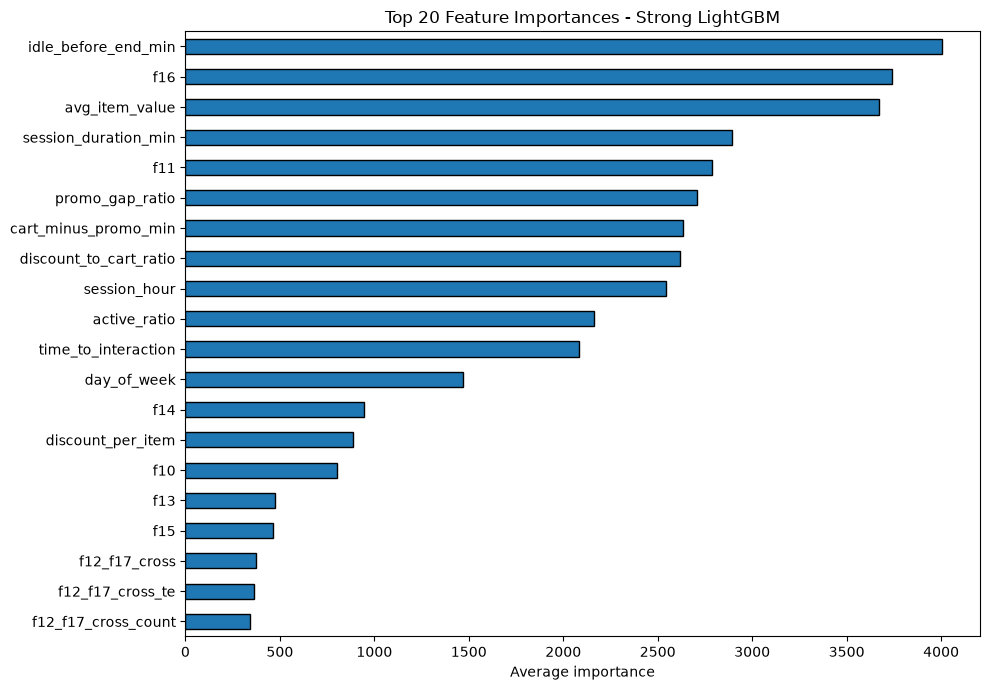


Top 20 features:
idle_before_end_min       4005.52
f16                       3737.50
avg_item_value            3670.52
session_duration_min      2890.90
f11                       2788.82
promo_gap_ratio           2707.14
cart_minus_promo_min      2631.92
discount_to_cart_ratio    2618.30
session_hour              2545.56
active_ratio              2163.92
time_to_interaction       2082.30
day_of_week               1471.40
f14                        947.04
discount_per_item          885.44
f10                        804.84
f13                        472.88
f15                        461.92
f12_f17_cross              371.56
f12_f17_cross_te           364.58
f12_f17_cross_count        342.24


In [32]:
avg_importance = (feature_importance_sum / feature_importance_count).sort_values(ascending=False)
 
plt.figure(figsize=(10, 7))
avg_importance.head(20).sort_values().plot(kind="barh", edgecolor="black")
plt.title("Top 20 Feature Importances - Strong LightGBM")
plt.xlabel("Average importance")
plt.tight_layout()
plt.savefig("feature_importance_strong_lgbm.png", dpi=150, bbox_inches="tight")
plt.show()
 
print()
print("Top 20 features:")
print(avg_importance.head(20).to_string())
 
feature_table = pd.DataFrame({
    "Feature": avg_importance.index,
    "Average_Importance": avg_importance.values,
})
feature_table.to_csv("feature_importance_table.csv", index=False)

In [34]:
feature_summary = pd.DataFrame({
    "Feature group": [
        "Time features",
        "Cart features",
        "Promotion features",
        "Interaction features",
        "Frequency/count encoding",
        "Target encoding",
    ],
    "Examples": [
        "session_duration_min, session_hour, is_weekend",
        "has_items, avg_item_value, discount_per_item",
        "has_promotion, promo_gap_ratio, accepted_strong_promo",
        "items_and_accepted, over30_and_items, f12_f17_cross",
        "category_count and category_freq features",
        "fold-safe average target values for selected categories",
    ],
    "Purpose": [
        "Capture when and how long the user session was",
        "Represent basket size and cart value",
        "Measure promotion presence and strength",
        "Capture combined behaviors that may indicate ordering",
        "Show how common each category or combination is",
        "Use category-level order behavior without data leakage",
    ],
})
 
print()
print("Feature engineering summary")
print(feature_summary.to_string(index=False))
 
feature_summary.to_csv("feature_engineering_summary.csv", index=False)


Feature engineering summary
           Feature group                                                Examples                                                Purpose
           Time features          session_duration_min, session_hour, is_weekend         Capture when and how long the user session was
           Cart features            has_items, avg_item_value, discount_per_item                   Represent basket size and cart value
      Promotion features   has_promotion, promo_gap_ratio, accepted_strong_promo                Measure promotion presence and strength
    Interaction features     items_and_accepted, over30_and_items, f12_f17_cross  Capture combined behaviors that may indicate ordering
Frequency/count encoding               category_count and category_freq features        Show how common each category or combination is
         Target encoding fold-safe average target values for selected categories Use category-level order behavior without data leakage


In [35]:
if SAVE_SUBMISSION:
    submission = pd.DataFrame({
        "id": test_ids,
        "order_placed": all_test_preds,
    })
    submission.to_csv("submission.csv", index=False)
    print()
    print("submission.csv saved")
    print("Predicted order rate:", round(all_test_preds.mean() * 100, 3), "%")
else:
    print()
    print("Submission was not saved because SAVE_SUBMISSION is False.")


submission.csv saved
Predicted order rate: 2.926 %
